In [1]:
print("Hello, Data Science!")

Hello, Data Science!


In [4]:
%pip install pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
print("All libraries imported succefully")

All libraries imported succefully


In [3]:
orders = pd.read_csv(r"ecommerce_orders.csv")

In [4]:
customers = pd.read_csv(r"ecommerce_customers.csv")

In [5]:
print("ORDERS DATASET")
display(orders.head())

print("\nCUSTOMERS DATASET")
display(customers.head())

ORDERS DATASET


,order_id,customer_id,product_name,quantity,price,total_amount,payment_method,order_date,delivery_city
0,1,123,Laptop,4,50000.0,200000.0,Card,2025-08-16,Port Harcourt
1,2,152,Mouse,3,NaN,NaN,Card,2025-05-22,Kano
2,3,148,Tablet,4,25000.0,100000.0,Card,2025-10-08,NaN
3,4,55,Laptop,3,50000.0,150000.0,Cash,2025-10-17,Port Harcourt
4,5,88,Headphones,3,10000.0,30000.0,Card,2026-04-03,NaN



CUSTOMERS DATASET


,customer_id,customer_name,email,phone_number,city,gender,signup_date
0,1,Carolyn Ortiz,jameslarsen@andersen.com,158.169.1187x566,Kano,Female,2024-10-04
1,2,Jonathan Kim,quinnmichael@holt.com,123-402-9208x4778,NaN,NaN,2023-07-24
2,3,Louis Ruiz,mullenmary@garcia.com,(542)561-3403x3630,Abuja,NaN,2025-06-20
3,4,Teresa Castillo,murraygregory@lopez-bailey.com,837.920.0294x6636,NaN,NaN,2025-02-21
4,5,Ruth Montgomery,tarameyer@price.biz,117-242-8219,Lagos,Male,2025-04-18


In [6]:
total_revenue = orders["total_amount"].sum()
print("Total Revenue: #", total_revenue)

Total Revenue: # 11340000.0


In [8]:
total_orders = orders["order_id"].nunique()

average_order_value = total_revenue / total_orders

print("Total Orders:", total_orders)
print("Average Order Value: #", average_order_value)

Total Orders: 200
Average Order Value: # 56700.0


In [10]:
top_products =(
    orders.groupby("product_name")
["total_amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products)

product_name
Laptop        2090000.0
Keyboard      2065000.0
Headphones    1710000.0
Monitor       1615000.0
Phone         1380000.0
Tablet        1295000.0
Mouse         1185000.0
Name: total_amount, dtype: float64

In [11]:
print(orders.columns.tolist())

['order_id', 'customer_id', 'product_name', 'quantity', 'price', 'total_amount', 'payment_method', 'order_date', 'delivery_city']


In [25]:
highest_revenue = (
    orders.groupby("product_name")["total_amount"]
    .sum()
    .idxmax()
)
print(highest_revenue)

Laptop


In [26]:
print(orders["delivery_city"].unique())

<ArrowStringArray>
['Port Harcourt', 'Kano', nan, 'Abuja', 'Lagos', 'Ibadan']
Length: 6, dtype: str


In [28]:
city_revenue = (
    orders.groupby("delivery_city")
["total_amount"]
    .sum()
    .idxmax()
)
display(city_revenue)

'Abuja'

In [30]:
most_used_payment = orders["payment_method"].mode()[0]

print(most_used_payment)

PayPal


In [33]:
orders["order_date"] = pd.to_datetime(orders["order_date"])

In [45]:
orders["month"] = orders["order_date"].dt.to_period("M")

In [50]:
monthly_sales = orders.groupby("month")["total_amount"].sum()

In [51]:
display(monthly_sales.sort_values(ascending=False))

month
2025-10    1420000.0
2025-08    1405000.0
2026-03    1250000.0
2026-04    1020000.0
2025-07    1010000.0
2025-09    1010000.0
2025-05     825000.0
2026-02     820000.0
2025-12     815000.0
2026-01     725000.0
2026-05     625000.0
2025-11     285000.0
2025-06     130000.0
Freq: M, Name: total_amount, dtype: float64

In [52]:
best_month = monthly_sales.idxmax()
print("Month with Highest Sales:", best_month)

Month with Highest Sales: 2025-10


In [53]:
customer_orders = orders["customer_id"].value_counts()
display(customer_orders.head(10))

customer_id
110    5
101    4
156    4
84     4
97     4
123    3
29     3
201    3
184    3
173    3
Name: count, dtype: int64

In [54]:
top_customer_id = customer_orders.idxmax()
print("customer ID with Most Orders:", top_customer_id)

customer ID with Most Orders: 110


In [57]:
top_customer = customers[
    customers["customer_id"] ==
top_customer_id
    ]
display(top_customer[["customer_id","customer_name"]])

,customer_id,customer_name
109,110,Curtis Lopez


In [58]:
customer_revenue = pd.merge(
    orders,
    customers[["customer_id", "customer_name"]],
    on="customer_id",
    how="left"
)

In [59]:
top_5_customers = (
    customer_revenue.groupby(["customer_id", "customer_name"])["total_amount"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

display(top_5_customers)

customer_id  customer_name  
81           Donald Hamilton    400000.0
173          Jill Lee           350000.0
97           Mike Walsh         350000.0
156          Lindsay Rowe       320000.0
82           Joan Hernandez     275000.0
Name: total_amount, dtype: float64

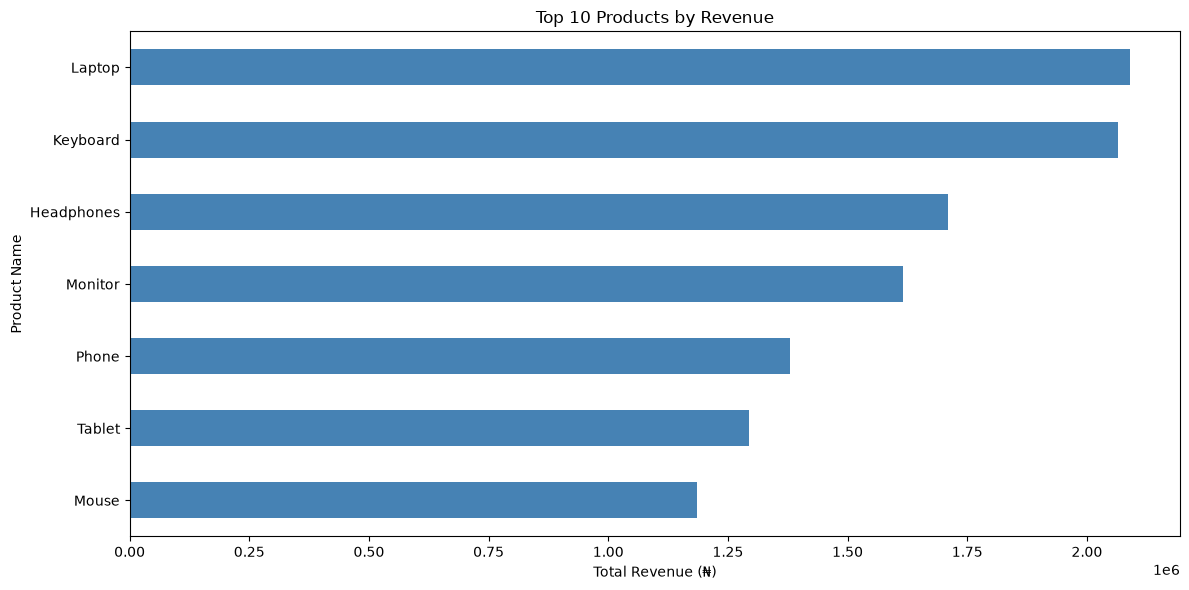

In [60]:
plt.figure(figsize=(12, 6))

top_products.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue (₦)")
plt.ylabel("Product Name")

plt.tight_layout()
plt.show()

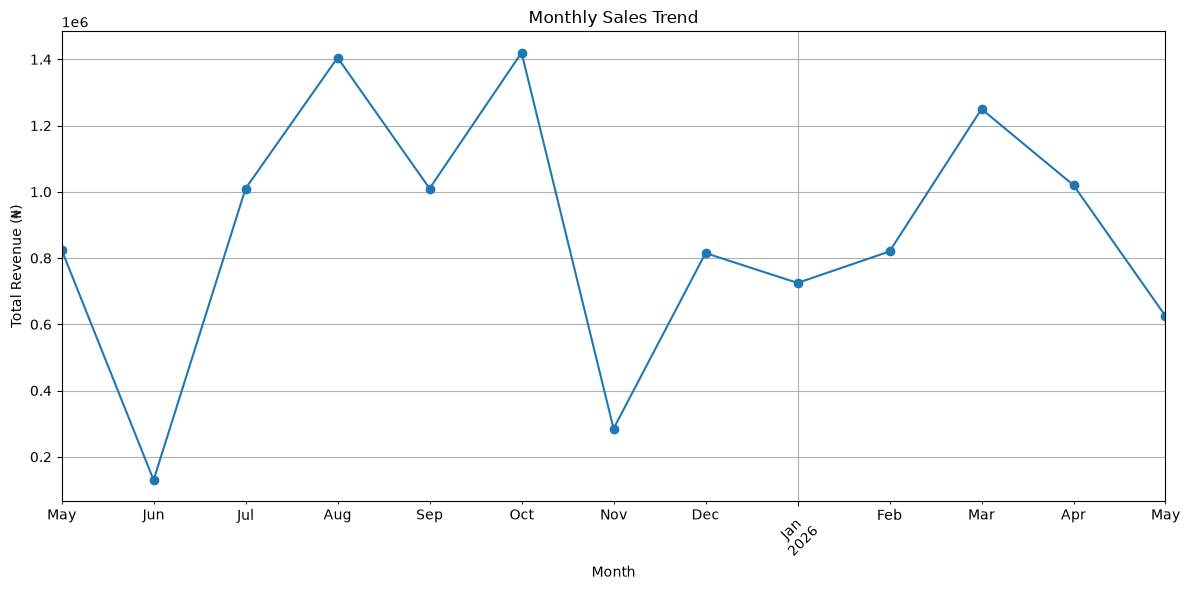

In [61]:
plt.figure(figsize=(12, 6))

monthly_sales.sort_index().plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue (₦)")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [62]:
plt.figure(figsize=(8, 8))

payment_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Payment Method Distribution")
plt.ylabel("")

plt.tight_layout()
plt.show()

NameError: name 'payment_counts' is not defined

<Figure size 800x800 with 0 Axes>

In [63]:
payment_counts = orders["payment_method"].value_counts()

display(payment_counts)

payment_method
PayPal      53
Cash        51
Card        49
Transfer    47
Name: count, dtype: int64

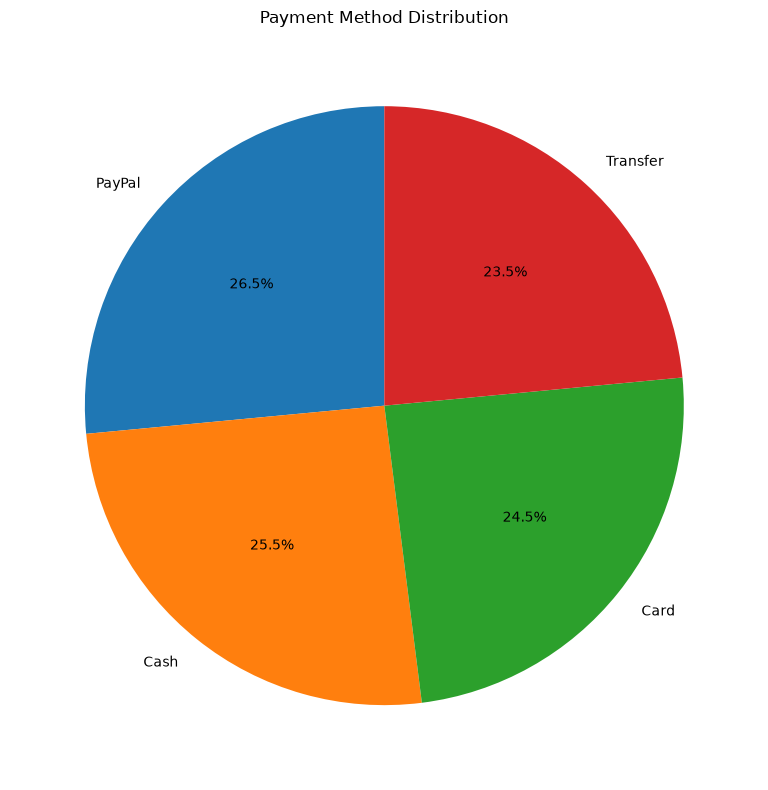

In [64]:
plt.figure(figsize=(8, 8))

payment_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Payment Method Distribution")
plt.ylabel("")

plt.tight_layout()
plt.show()

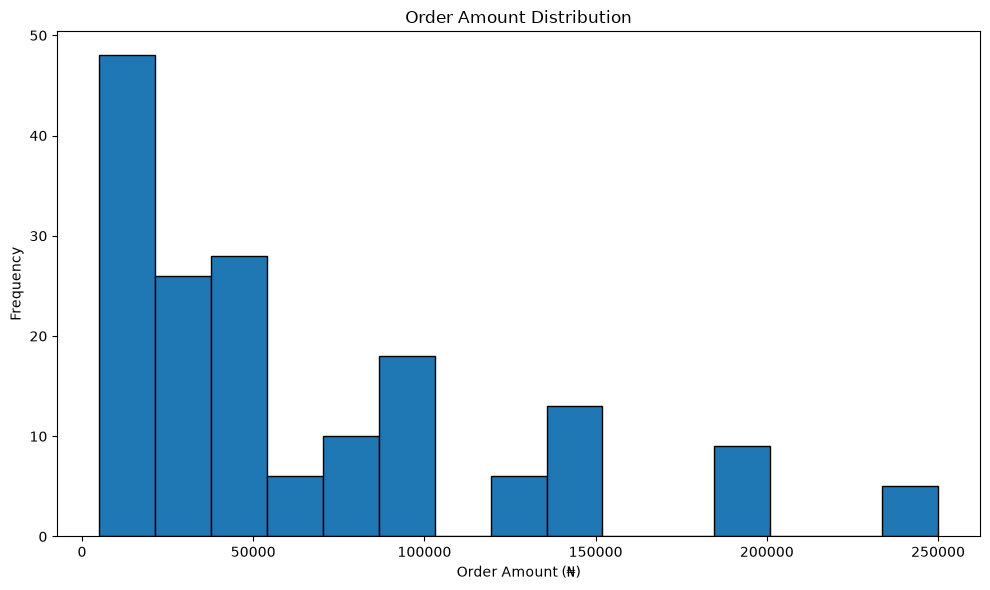

In [65]:
plt.figure(figsize=(10, 6))

orders["total_amount"].dropna().plot(
    kind="hist",
    bins=15,
    edgecolor="black"
)

plt.title("Order Amount Distribution")
plt.xlabel("Order Amount (₦)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

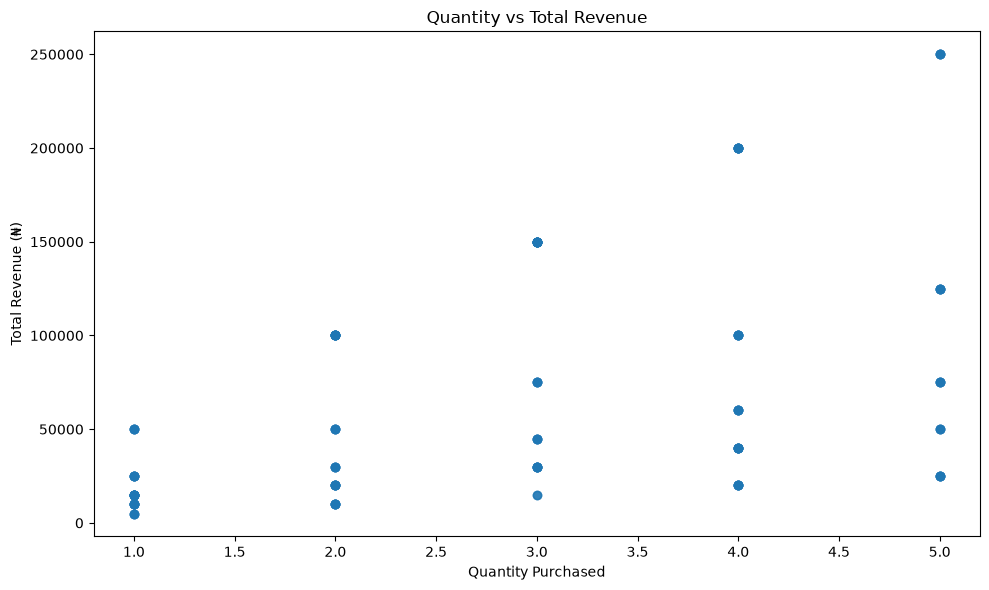

In [66]:
plt.figure(figsize=(10, 6))

plt.scatter(
    orders["quantity"],
    orders["total_amount"],
    alpha=0.7
)

plt.title("Quantity vs Total Revenue")
plt.xlabel("Quantity Purchased")
plt.ylabel("Total Revenue (₦)")

plt.tight_layout()
plt.show()